 Amazon Fine Food Reviews: Text Analytics Project



**Dataset:** https://www.kaggle.com/snap/amazon-fine-food-reviews, file `Reviews.csv`


---
# Part 1: Model Selection and Dataset Justification

## 1.1 Model Selection

### A. Identifying key themes (areas of concern and praise)

**Selected model: Latent Dirichlet Allocation (LDA) topic modelling**, 

 **Why it suits text data** - LDA treats every review as a mixture of hidden topics and every topic as a distribution over words. Reviews are naturally bags of words about a few subjects (taste, packaging, price, delivery), so this structure fits well. It is unsupervised, so it needs no labelled themes. 
 **Strengths** - Finds themes without labels; each topic is a readable list of words; every review gets a topic mix, so we can measure how common each theme is and how negative it is; scales to large corpora. 
 **Limitations**  -The number of topics must be chosen in advance; topics can be vague or overlap and need human interpretation; ignores word order; short reviews give unstable topic estimates; results vary with random seed. 
**Expected outputs**  - A set of topics, each with its top words (for example *coffee / flavour / roast*, *dog / treats / chewing*, *shipping / box / damaged*); for each topic, the share of reviews and the percentage of negative reviews. This points to which product areas drive praise or complaints. 

*Alternatives considered:* K-Means clustering on TF-IDF (hard clusters, less natural for reviews that mention several subjects) and BERTopic (better quality, but heavy to run and harder to explain to a business audience).

### B. Sentiment analysis

**Selected models: Logistic Regression on TF-IDF features (main model), with Multinomial Naive Bayes as a baseline.**


 **Why it suits text data** - Text becomes a very high-dimensional, sparse vector (one dimension per word or phrase). Linear models are known to work very well in this setting, train fast on hundreds of thousands of reviews, and handle sparse input efficiently. Naive Bayes is the classic baseline for text classification. 
 **Strengths** - Fast and scalable; strong accuracy on review sentiment; **interpretable**, because the coefficients show which words push a review towards positive or negative (this is valuable to the business); `class_weight` can handle imbalance; low risk of overfitting with regularisation. 
 **Limitations** - Bag-of-words ignores word order and context, so it struggles with sarcasm ("great, it broke in a day") and complex negation; it cannot capture meaning beyond the n-grams it has seen; reviews are imbalanced (mostly positive), so accuracy alone is misleading. |
 **Expected outputs** - A positive or negative prediction (and a probability) for each review; accuracy, precision, recall, F1 and a confusion matrix; ranked lists of the most positive and most negative words and phrases. 

*Alternatives considered:* LSTM and Transformer models (such as BERT) usually give higher accuracy and handle context, but need GPUs, long training times and are far less interpretable. They are listed as future work.

## 1.2 Dataset Justification


 **Relevance** - The dataset holds real customer reviews of food products sold on Amazon, with a free-text review, a short summary and a 1 to 5 star score. This matches the scenario exactly, and the star score gives us a ready-made label for sentiment, so no manual labelling is needed. 
 **Data quality** - Few missing values (a handful of missing `ProfileName` and `Summary` entries); a **substantial number of duplicate reviews** (the same user, time and text posted under several product IDs), which must be removed; noise such as HTML tags (`<br />`), URLs and inconsistent punctuation; some rows where helpful votes exceed total votes. All are fixable in cleaning (Part 3). 
 **Size and diversity**  About 568,000 reviews from about 256,000 users on about 74,000 products over more than a decade (1999 to 2012), covering many food categories. That is large enough to train and evaluate models with confidence and to find varied topics. 
 **Ethical considerations** - **Privacy:** - the data has user IDs and profile names, so we do not use or publish them and report results in aggregate only. **Bias:** reviewers are self-selected and are not a representative sample of all customers; the data is heavily skewed towards 5-star reviews; star ratings are an imperfect proxy for sentiment, and some reviewers rate the seller or delivery rather than the product. **Fairness:** the data is mostly English and from one market, so conclusions may not generalise to other groups. Fake or incentivised reviews may also be present. These limitations are stated in the report. 

---
#  Planning the Analysis

##  Exploratory Data Analysis Plan

| Step | Action | Reason |
|---|---|---|
| Missing values | Count nulls per column; drop rows with missing review text; keep other missing fields (`Summary`, `ProfileName`) because they are not used by the model | Text is the only input that matters |
| Duplicates | Remove rows with the same `UserId`, `ProfileName`, `Time` and `Text`; also remove rows with `HelpfulnessNumerator` greater than `HelpfulnessDenominator` | Duplicates inflate counts and leak between train and test sets |
| Label creation | Score 4 to 5 = positive, score 1 to 2 = negative, score 3 = neutral and excluded | Gives a clear binary target |
| Lowercasing | Convert all text to lowercase | "Great" and "great" become one token |
| Remove noise | Strip HTML tags and URLs | They carry no sentiment |
| Removing punctuation | Remove digits, punctuation and symbols | Reduces vocabulary size |
| Stopword removal | Remove common words (the, and, is) **but keep negations** (not, no, nor, never) | Negations change meaning ("not good") |
| Visual EDA | Score distribution, review length distribution, word frequency plots, word clouds | Understand the data before modelling |

##  Feature Selection Plan

| Technique | Role in the plan |
|---|---|
| **Bag of Words** | Baseline: raw word counts. Also used for LDA, which needs counts. |
| **TF-IDF** | Main representation for classification: down-weights words that appear in almost every review and highlights distinctive words. |
| **N-grams (1 to 2)** | Capture short phrases such as "not good" and "highly recommend" that single words miss. |
| **Vocabulary limits** | `max_features` caps the vocabulary; `min_df` drops very rare words (typos). |

We compare Bag of Words with TF-IDF on the same split and keep the better one.

##  Model Training Plan

| Item | Plan |
|---|---|
| **Sampling** | Use a random sample of up to 100,000 cleaned reviews so that every model trains in minutes on a laptop |
| **Train-test split** | 80% train, 20% test, **stratified** by sentiment so both sets have the same positive/negative ratio; fixed `random_state=42` |
| **Leakage control** | The vectoriser is fitted on the training set only |
| **TF-IDF hyperparameters** | `max_features=20000`, `ngram_range=(1,2)`, `min_df=5`, `sublinear_tf=True` |
| **Logistic Regression** | `C` (regularisation strength) tuned over a small grid with 3-fold cross-validation; `max_iter=1000` |
| **Naive Bayes** | `alpha=1.0` (Laplace smoothing) |
| **LDA** | 8 topics, `max_features=5000`, `max_df=0.5`, `min_df=10` |
| **Epochs / learning rate** | Not needed: these are linear and probabilistic models solved directly, not trained with gradient descent epochs (they would apply to an LSTM or Transformer) |

##  Evaluation Plan

| Metric | Why |
|---|---|
| **Accuracy** | Overall share correct, but misleading on imbalanced data (a model that always says "positive" would score about 88%) |
| **Precision** | Of the reviews predicted negative, how many truly are |
| **Recall** | Of the truly negative reviews, how many we catch. Most important for the business, because missed complaints are costly |
| **F1-score** | Balance of precision and recall; we focus on the **negative class** and the **macro average** |
| **Confusion matrix** | Shows exactly which errors the model makes |

##  Reporting Plan

| Report section | Content |
|---|---|
| EDA insights | Cleaning results, rating balance, review lengths, common words |
| Visualisations | Charts for ratings, lengths, top words, word clouds, confusion matrix, topic charts |
| Model performance | Metrics table for baseline, main and improved models |
| Business recommendations | Actions linked to the themes of concern and praise and to the sentiment findings |

---
Conducting the Analysis

importing libraries

In [36]:
# Standard libraries
import re
import warnings
from collections import Counter





In [37]:
# Data handling
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns




In [38]:
# Scikit-learn: text features, models, evaluation
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

# Word clouds are optional: install with  pip install wordcloud
try:
    from wordcloud import WordCloud
    HAS_WORDCLOUD = True
except ImportError:
    HAS_WORDCLOUD = False

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
RANDOM_STATE = 42  # fixed seed so results can be reproduced

Exploratory Data Analysis

Loading the data and inspecting it

In [39]:
# Load the Amazon Fine Food Reviews dataset
df = pd.read_csv("Reviews.csv")
n_raw = len(df)

print("Shape:", df.shape)
df.head()

Shape: (568454, 10)


,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...


In [40]:
# Structure, data types and missing values
df.info()
print("\nMissing values per column:")
print(df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 568454 entries, 0 to 568453
Data columns (total 10 columns):
 #   Column                  Non-Null Count   Dtype
---  ------                  --------------   -----
 0   Id                      568454 non-null  int64
 1   ProductId               568454 non-null  str  
 2   UserId                  568454 non-null  str  
 3   ProfileName             568428 non-null  str  
 4   HelpfulnessNumerator    568454 non-null  int64
 5   HelpfulnessDenominator  568454 non-null  int64
 6   Score                   568454 non-null  int64
 7   Time                    568454 non-null  int64
 8   Summary                 568427 non-null  str  
 9   Text                    568454 non-null  str  
dtypes: int64(5), str(5)
memory usage: 313.1 MB

Missing values per column:
Id                         0
ProductId                  0
UserId                     0
ProfileName               26
HelpfulnessNumerator       0
HelpfulnessDenominator     0
Score                     

### Data cleaning
Steps: drop rows with no review text, remove duplicate reviews, remove rows with impossible helpfulness counts, and create the sentiment label.

In [41]:
# 1. Drop rows where the review text is missing (the text is our model input)
df = df.dropna(subset=["Text"])

# 2. Remove duplicate reviews: the same user posting the same text at the same time
#    (this happens when one review is copied across several product variants)
before = len(df)
df = df.drop_duplicates(subset=["UserId", "ProfileName", "Time", "Text"])
print(f"Duplicates removed: {before - len(df):,}")

# 3. Remove rows with impossible data (helpful votes cannot exceed total votes)
df = df[df["HelpfulnessNumerator"] <= df["HelpfulnessDenominator"]]

# 4. Create the sentiment label from the star score
#    4-5 stars = positive (1), 1-2 stars = negative (0), 3 stars = neutral and dropped
df = df[df["Score"] != 3].copy()
df["sentiment"] = (df["Score"] >= 4).astype(int)

n_clean = len(df)
pct_pos = df["sentiment"].mean() * 100
pct_neg = 100 - pct_pos
print(f"Raw reviews: {n_raw:,}")
print(f"After cleaning (3-star removed): {n_clean:,}")
print(f"Positive: {pct_pos:.1f}%   Negative: {pct_neg:.1f}%")

Duplicates removed: 174,521
Raw reviews: 568,454
After cleaning (3-star removed): 364,162
Positive: 84.3%   Negative: 15.7%


In [42]:
# 5. Work on a random sample so that models train quickly (use all rows by setting SAMPLE_SIZE = None)
SAMPLE_SIZE = 100000
if SAMPLE_SIZE and len(df) > SAMPLE_SIZE:
    df = df.sample(SAMPLE_SIZE, random_state=RANDOM_STATE)
df = df.reset_index(drop=True)
n_sample = len(df)
print("Rows used in the analysis:", f"{n_sample:,}")

Rows used in the analysis: 100,000


### Text normalisation
Each review is lowercased, stripped of HTML and URLs, stripped of punctuation and digits, and stopwords are removed. **Negation words are kept** because "not good" and "good" have opposite meanings.

In [43]:
# Build the stopword list: sklearn's English list, but keep negations
negations = {"not", "no", "nor", "never", "none", "nothing", "cannot"}
STOPWORDS = set(ENGLISH_STOP_WORDS) - negations

def clean_text(text):
    # Normalise one review into a clean string of lowercase words
    text = text.lower()                          # lowercasing
    text = re.sub(r"<[^>]+>", " ", text)         # remove HTML tags such as <br />
    text = re.sub(r"http\S+|www\.\S+", " ", text)  # remove URLs
    text = re.sub(r"n't\b", " not", text)        # "don't" -> "do not" so negation survives
    text = re.sub(r"[^a-z\s]", " ", text)        # remove punctuation, digits and symbols
    words = [w for w in text.split() if w not in STOPWORDS and len(w) > 1]  # stopword removal
    return " ".join(words)

df["clean_text"] = df["Text"].apply(clean_text)

# Show a before / after example
example = df.loc[0]
print("ORIGINAL:", example["Text"][:250])
print("CLEANED :", example["clean_text"][:250])

ORIGINAL: Excellent, clean taste with honey flavor lasting throughout the pallet.  Taste is worth the money.  Delivery was timely and packaged for product protection.
CLEANED : excellent clean taste honey flavor lasting pallet taste worth money delivery timely packaged product protection


### Visualisation 1: Distribution of star ratings and sentiment

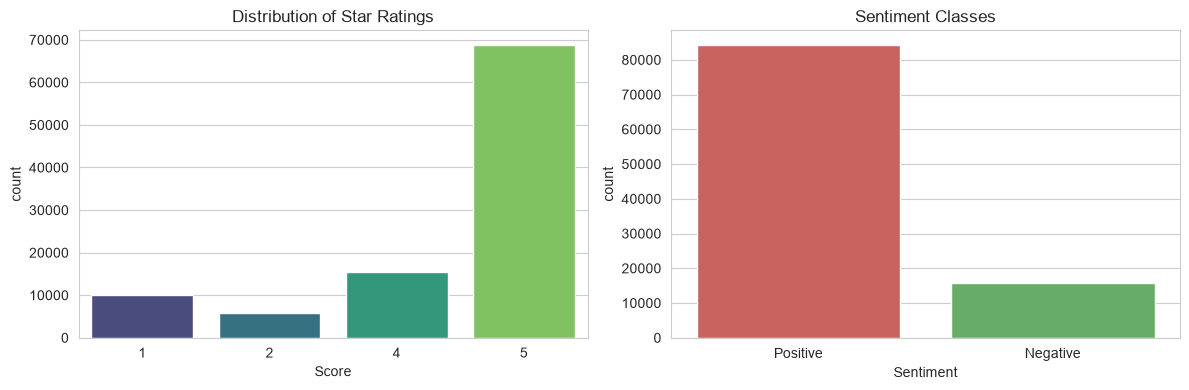

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Star score counts
sns.countplot(x="Score", data=df, ax=axes[0], palette="viridis")
axes[0].set_title("Distribution of Star Ratings")

# Sentiment class counts (shows the class imbalance)
sns.countplot(x=df["sentiment"].map({0: "Negative", 1: "Positive"}), ax=axes[1], palette=["#d9534f", "#5cb85c"])
axes[1].set_title("Sentiment Classes")
axes[1].set_xlabel("Sentiment")
plt.tight_layout()
plt.show()

**Insight:** reviews are strongly skewed towards positive ratings (5 stars is the most common score), so the sentiment classes are **imbalanced**. Accuracy alone will therefore be misleading, and we will pay close attention to precision, recall and F1 for the minority negative class.

### Visualisation 2: Review length distribution

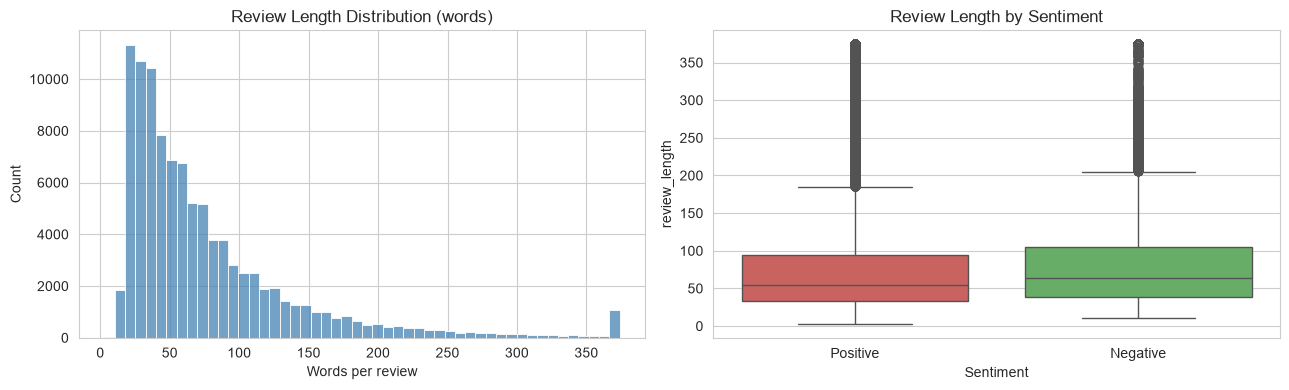

             count  mean   std   min   25%   50%    75%     max
sentiment                                                      
0          15762.0  85.1  78.9  11.0  38.0  64.0  105.0  1751.0
1          84238.0  77.2  75.8   3.0  33.0  54.0   94.0  2520.0


In [45]:
# Number of words in each original review
df["review_length"] = df["Text"].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Overall distribution (clipped at the 99th percentile so a few huge reviews do not flatten the chart)
upper = df["review_length"].quantile(0.99)
sns.histplot(df["review_length"].clip(upper=upper), bins=50, ax=axes[0], color="steelblue")
axes[0].set_title("Review Length Distribution (words)")
axes[0].set_xlabel("Words per review")

# Length by sentiment
sns.boxplot(x=df["sentiment"].map({0: "Negative", 1: "Positive"}), y=df["review_length"].clip(upper=upper), ax=axes[1],
            palette=["#d9534f", "#5cb85c"])
axes[1].set_title("Review Length by Sentiment")
axes[1].set_xlabel("Sentiment")
plt.tight_layout()
plt.show()

print(df.groupby("sentiment")["review_length"].describe().round(1))

**Insight:** review length is right-skewed: most reviews are short, with a long tail of very detailed ones. Compare the two boxes above: negative reviews tend to be longer than positive ones, as unhappy customers usually explain what went wrong.

### Visualisation 3: Word frequency plots

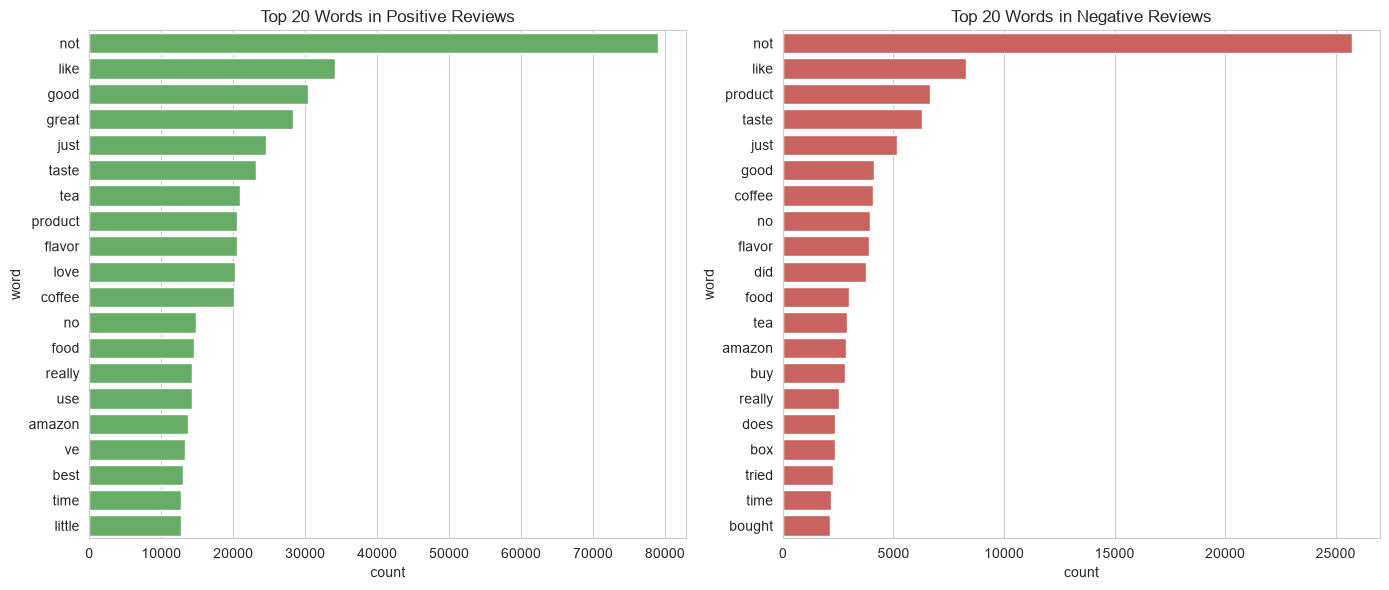

In [46]:
def top_words(texts, n=20):
    # Count the most common words in a collection of cleaned reviews
    counter = Counter(" ".join(texts).split())
    return pd.DataFrame(counter.most_common(n), columns=["word", "count"])

# Extra words that are very common in every review but say little (for plotting only)
generic = {"br", "like", "just", "ve", "really", "get", "one", "use", "make", "bought", "buy"}

pos_words = top_words(df.loc[df.sentiment == 1, "clean_text"], 20)
neg_words = top_words(df.loc[df.sentiment == 0, "clean_text"], 20)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(data=pos_words, x="count", y="word", ax=axes[0], color="#5cb85c")
axes[0].set_title("Top 20 Words in Positive Reviews")
sns.barplot(data=neg_words, x="count", y="word", ax=axes[1], color="#d9534f")
axes[1].set_title("Top 20 Words in Negative Reviews")
plt.tight_layout()
plt.show()

**Insight:** the most frequent words are shared across both groups (for example product, taste, flavour), so raw frequency does not separate happy from unhappy customers well. This is one reason we use **TF-IDF and a classifier** to find the words that actually distinguish the classes (see Part 4).

### Visualisation 4: Word clouds

In [47]:
# Word clouds show the most frequent words as larger text
if HAS_WORDCLOUD:
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    for ax, label, title, cmap in [(axes[0], 1, "Positive Reviews", "Greens"),
                                   (axes[1], 0, "Negative Reviews", "Reds")]:
        text = " ".join(df.loc[df.sentiment == label, "clean_text"].sample(min(20000, (df.sentiment == label).sum()),
                                                                           random_state=RANDOM_STATE))
        wc = WordCloud(width=700, height=450, background_color="white", colormap=cmap, max_words=100).generate(text)
        ax.imshow(wc, interpolation="bilinear")
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("wordcloud is not installed. Run:  pip install wordcloud  and re-run this cell.")

wordcloud is not installed. Run:  pip install wordcloud  and re-run this cell.


## Feature Engineering

Machine learning models need numbers, so each review is converted into a numeric vector.

**Approach and justification**
- **Bag of Words (baseline):** counts how often each word appears. Simple, but common words dominate.
- **TF-IDF (main):** multiplies the word count by how rare the word is across all reviews, so distinctive words (such as *stale*, *delicious*) matter more than ubiquitous ones. `sublinear_tf=True` dampens the effect of a word repeated many times.
- **N-grams (1 to 2 words):** capture phrases such as *not good*, *highly recommend* and *waste money*, which carry sentiment that single words lose.
- **Vocabulary limits:** `max_features=20000` and `min_df=5` keep the strongest features, drop typos and keep the model fast.

To avoid **data leakage**, we split the data first and fit the vectoriser only on the training set.

In [48]:
# Split into train and test sets BEFORE building features (stratify keeps the class ratio equal in both)
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["clean_text"], df["sentiment"],
    test_size=0.2, random_state=RANDOM_STATE, stratify=df["sentiment"])

print("Train size:", len(X_train_text), "  Test size:", len(X_test_text))
print("Positive share  train: %.3f   test: %.3f" % (y_train.mean(), y_test.mean()))

Train size: 80000   Test size: 20000
Positive share  train: 0.842   test: 0.842


In [49]:
# Main features: TF-IDF with unigrams and bigrams
tfidf = TfidfVectorizer(max_features=20000,     # keep the 20,000 strongest terms
                        ngram_range=(1, 2),     # single words and two-word phrases
                        min_df=5,               # ignore terms appearing in fewer than 5 reviews
                        sublinear_tf=True)      # use 1 + log(tf) so repeated words do not dominate
X_train_tfidf = tfidf.fit_transform(X_train_text)   # learn vocabulary on TRAIN only
X_test_tfidf = tfidf.transform(X_test_text)         # apply the same vocabulary to TEST

# Baseline features: plain Bag of Words (unigrams only), for comparison
bow = CountVectorizer(max_features=20000, min_df=5)
X_train_bow = bow.fit_transform(X_train_text)
X_test_bow = bow.transform(X_test_text)

print("TF-IDF matrix shape (train):", X_train_tfidf.shape)
print("Bag-of-words matrix shape (train):", X_train_bow.shape)
print("Example n-gram features:", list(tfidf.get_feature_names_out()[5000:5010]))

TF-IDF matrix shape (train): (80000, 20000)
Bag-of-words matrix shape (train): (80000, 16215)
Example n-gram features: ['dusting', 'dusty', 'dutch', 'duty', 'dv', 'dvd', 'dye', 'dyed', 'dyes', 'dying']


In [50]:
# Justify the choice: compare Bag of Words with TF-IDF using the same classifier
lr_bow = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE).fit(X_train_bow, y_train)
lr_tfidf = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE).fit(X_train_tfidf, y_train)

feature_compare = pd.DataFrame({
    "Features": ["Bag of Words", "TF-IDF (1-2 grams)"],
    "Accuracy": [accuracy_score(y_test, lr_bow.predict(X_test_bow)),
                 accuracy_score(y_test, lr_tfidf.predict(X_test_tfidf))],
    "Macro F1": [f1_score(y_test, lr_bow.predict(X_test_bow), average="macro"),
                 f1_score(y_test, lr_tfidf.predict(X_test_tfidf), average="macro")],
}).round(4)
feature_compare

,Features,Accuracy,Macro F1
0,Bag of Words,0.9196,0.8396
1,TF-IDF (1-2 grams),0.9291,0.8491


**Result:** the table above compares the two representations with the same classifier. TF-IDF with n-grams is normally equal or better, and it is the one we use for the rest of the project.

## Model Training

We train two sentiment classifiers on the TF-IDF features, using the hyperparameters chosen in the plan:

1. **Multinomial Naive Bayes** (`alpha=1.0`): fast baseline.
2. **Logistic Regression** (`C=1.0`, `max_iter=1000`): main model.

In [51]:
# Model 1: Multinomial Naive Bayes (baseline)
nb_model = MultinomialNB(alpha=1.0)          # alpha = Laplace smoothing
nb_model.fit(X_train_tfidf, y_train)         # learn word probabilities per class

# Model 2: Logistic Regression (main model)
lr_model = LogisticRegression(C=1.0,         # inverse regularisation strength
                              max_iter=1000, # enough iterations to converge
                              random_state=RANDOM_STATE)
lr_model.fit(X_train_tfidf, y_train)

# Predict on the unseen test set
nb_pred = nb_model.predict(X_test_tfidf)
lr_pred = lr_model.predict(X_test_tfidf)
print("Both models trained.")

Both models trained.


### Theme discovery with LDA topic modelling
LDA needs raw word **counts** (not TF-IDF), so we build a separate count matrix. We use a sample of 20,000 reviews and 8 topics (see plan).

In [52]:
# Extra stopwords for topic modelling: words that appear everywhere and blur the topics
topic_stop = list(STOPWORDS | {"br", "like", "just", "really", "good", "great", "love", "ve", "product", "amazon",
                               "buy", "bought", "use", "used", "make", "made", "got", "get", "think", "will", "way",
                               "time", "better", "little", "bit", "much", "also", "ordered", "order", "found", "try"})

lda_sample = df.sample(min(20000, len(df)), random_state=RANDOM_STATE).reset_index(drop=True)

# Count matrix: ignore very rare words (min_df) and words in more than half of all reviews (max_df)
count_vec = CountVectorizer(max_features=5000, max_df=0.5, min_df=10, stop_words=topic_stop)
X_counts = count_vec.fit_transform(lda_sample["clean_text"])

# Fit LDA with 8 topics
N_TOPICS = 8
lda = LatentDirichletAllocation(n_components=N_TOPICS, random_state=RANDOM_STATE, learning_method="online", n_jobs=-1)
topic_dist = lda.fit_transform(X_counts)    # each row = topic mixture of one review

# Show the top 10 words of every topic
terms = count_vec.get_feature_names_out()
for i, comp in enumerate(lda.components_):
    top = [terms[j] for j in comp.argsort()[-10:][::-1]]
    print(f"Topic {i}: {', '.join(top)}")

Topic 0: add, milk, water, sugar, taste, salt, fat, flavor, snack, calories
Topic 1: dogs, treats, dog, treat, did, day, energy, long, work, feel
Topic 2: oil, organic, using, years, stores, jar, olive, live, grocery, company
Topic 3: food, dog, chicken, eat, cat, old, no, loves, does, cats
Topic 4: price, box, bag, store, shipping, no, did, bags, arrived, fresh
Topic 5: chocolate, taste, free, best, butter, delicious, mix, cookies, tried, gluten
Topic 6: tea, flavor, taste, drink, water, sugar, hot, sweet, candy, green
Topic 7: coffee, cup, cups, flavor, hair, taste, strong, tried, blend, best


**Naming the topics:** read the word lists above and give each topic a short business name (for example *Coffee and tea*, *Pet food*, *Snacks and sweets*, *Shipping and packaging*). Put your names in the dictionary in the next cell. Names depend on the actual output of your run, so they are left for you to fill in.

In [53]:
# Replace these defaults with your own labels after reading the topic words above,
# e.g. topic_names = {0: "Coffee and tea", 1: "Pet food", ...}
topic_names = {i: f"Topic {i}" for i in range(N_TOPICS)}

# Assign every review to its dominant topic, then measure how negative each topic is
lda_sample["topic"] = topic_dist.argmax(axis=1)
topic_summary = (lda_sample.groupby("topic")
                 .agg(reviews=("sentiment", "size"),
                      pct_negative=("sentiment", lambda s: (1 - s.mean()) * 100),
                      avg_stars=("Score", "mean"))
                 .round(1))
topic_summary["share_of_reviews_%"] = (topic_summary["reviews"] / len(lda_sample) * 100).round(1)
topic_summary.index = [topic_names[i] for i in topic_summary.index]
topic_summary = topic_summary.sort_values("pct_negative", ascending=False)
topic_summary

,reviews,pct_negative,avg_stars,share_of_reviews_%
Topic 4,3134,25.9,3.9,15.7
Topic 1,1283,17.3,4.2,6.4
Topic 3,1886,16.1,4.3,9.4
Topic 7,1730,15.2,4.2,8.6
Topic 6,3636,14.9,4.3,18.2
Topic 2,587,13.1,4.4,2.9
Topic 5,4949,13.1,4.4,24.7
Topic 0,2795,9.0,4.5,14.0


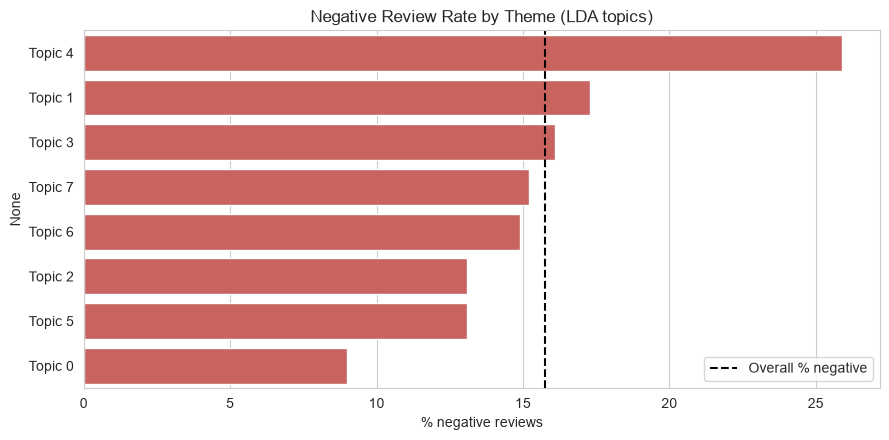

In [54]:
# Visualise: which themes carry the highest share of negative reviews?
plt.figure(figsize=(9, 4.5))
sns.barplot(x=topic_summary["pct_negative"], y=topic_summary.index, color="#d9534f")
plt.axvline(100 - df["sentiment"].mean() * 100, color="black", linestyle="--", label="Overall % negative")
plt.xlabel("% negative reviews")
plt.title("Negative Review Rate by Theme (LDA topics)")
plt.legend()
plt.tight_layout()
plt.show()

---
# Model Evaluation and Improvement



In [55]:
def evaluate(name, y_true, y_pred):
    # Return the main metrics for one model; negative class (0) is the minority class we care about
    return {"Model": name,
            "Accuracy": accuracy_score(y_true, y_pred),
            "Precision (neg)": precision_score(y_true, y_pred, pos_label=0),
            "Recall (neg)": recall_score(y_true, y_pred, pos_label=0),
            "F1 (neg)": f1_score(y_true, y_pred, pos_label=0),
            "Macro F1": f1_score(y_true, y_pred, average="macro")}

results = pd.DataFrame([evaluate("Naive Bayes (baseline)", y_test, nb_pred),
                        evaluate("Logistic Regression", y_test, lr_pred)]).set_index("Model").round(4)
results

,Accuracy,Precision (neg),Recall (neg),F1 (neg),Macro F1
Model,,,,,
Naive Bayes (baseline),0.8976,0.9126,0.3877,0.5442,0.7433
Logistic Regression,0.9291,0.8796,0.6374,0.7391,0.8491


In [56]:
# Full classification report for the main model
print(classification_report(y_test, lr_pred, target_names=["Negative", "Positive"], digits=3))

              precision    recall  f1-score   support

    Negative      0.880     0.637     0.739      3152
    Positive      0.935     0.984     0.959     16848

    accuracy                          0.929     20000
   macro avg      0.908     0.811     0.849     20000
weighted avg      0.927     0.929     0.924     20000



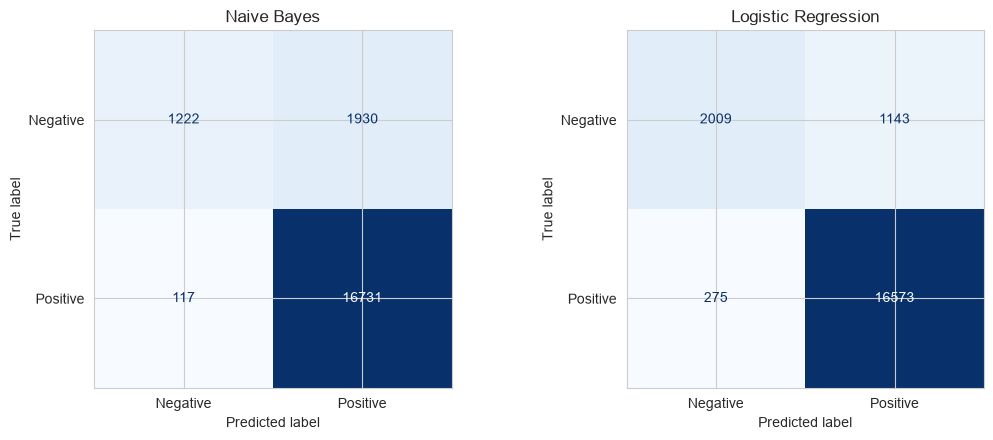

In [57]:
# Confusion matrices for both models side by side
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, name, pred in [(axes[0], "Naive Bayes", nb_pred), (axes[1], "Logistic Regression", lr_pred)]:
    cm = confusion_matrix(y_test, pred)
    ConfusionMatrixDisplay(cm, display_labels=["Negative", "Positive"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

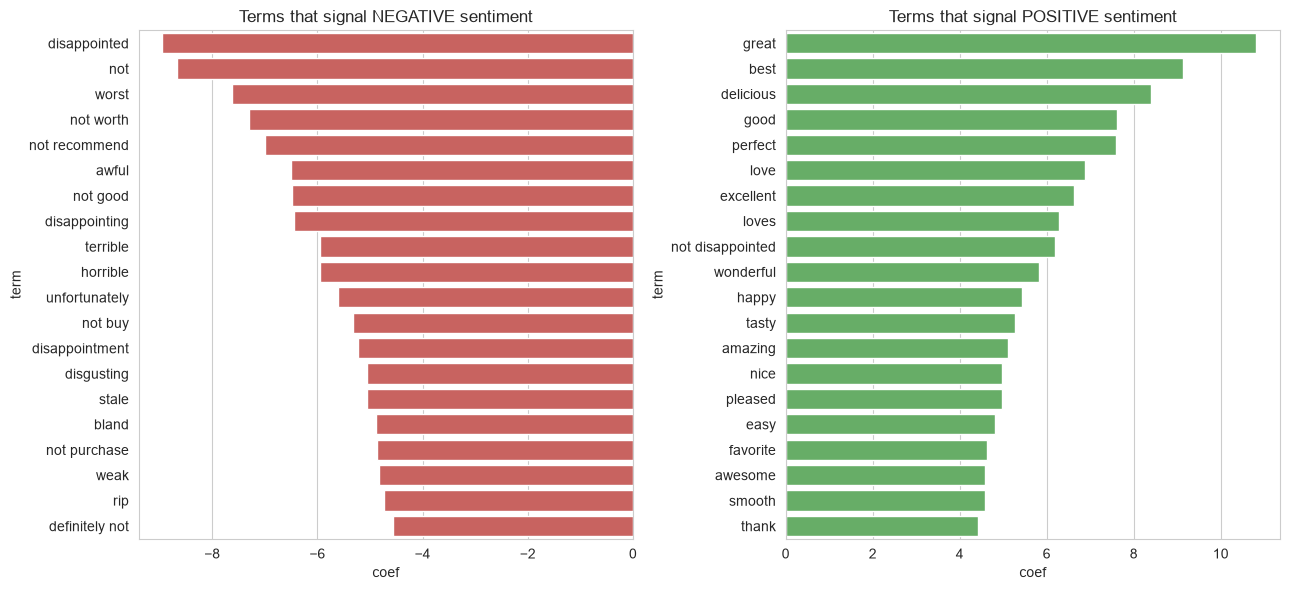

In [58]:
# Interpretability: words and phrases with the strongest influence in Logistic Regression
feature_names = tfidf.get_feature_names_out()
coefs = lr_model.coef_[0]
order = coefs.argsort()

top_negative = [(feature_names[i], round(coefs[i], 2)) for i in order[:20]]           # most negative
top_positive = [(feature_names[i], round(coefs[i], 2)) for i in order[::-1][:20]]     # most positive

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
neg_df = pd.DataFrame(top_negative, columns=["term", "coef"])
pos_df = pd.DataFrame(top_positive, columns=["term", "coef"])
sns.barplot(data=neg_df, x="coef", y="term", ax=axes[0], color="#d9534f")
axes[0].set_title("Terms that signal NEGATIVE sentiment")
sns.barplot(data=pos_df, x="coef", y="term", ax=axes[1], color="#5cb85c")
axes[1].set_title("Terms that signal POSITIVE sentiment")
plt.tight_layout()
plt.show()

In [59]:
# Look at some mistakes to understand the weaknesses
errors = pd.DataFrame({"review": X_test_text.values, "actual": y_test.values, "predicted": lr_pred})
errors = errors[errors.actual != errors.predicted]
print("Total errors:", len(errors), "of", len(y_test))
print("\nExamples of misclassified reviews:\n")
for _, row in errors.sample(min(4, len(errors)), random_state=RANDOM_STATE).iterrows():
    label = {0: "negative", 1: "positive"}
    print(f"[actual: {label[row.actual]}, predicted: {label[row.predicted]}] {row.review[:200]}...\n")

Total errors: 1418 of 20000

Examples of misclassified reviews:

[actual: negative, predicted: positive] gift husband grew candy stale arrived review stated violet candy box taste smell violet probably packaged separately not just tossed box...

[actual: negative, predicted: positive] changed box world greatest cracker piece flimsy cardboard cannot stand rigors shipping shelving carrying home groceries plastic bag everytime open new box damaged crackers pkgs inside tears just switc...

[actual: positive, predicted: negative] main manufacturer never product sale dependable...

[actual: negative, predicted: positive] did not wanted buy rawhide friend gave pup dingo loved forced brought bag dingo dental bones month ago stitch loved loved actually spent good minutes hours dingo dental bone did not really like red dy...



### Interpretation of the results

**Metrics**
- **Accuracy** is high for both models, but because most reviews are positive, a model that always answered "positive" would already score close to 88%. Accuracy therefore overstates quality.
- **Precision (negative)** tells us how trustworthy a "negative" flag is; **recall (negative)** tells us how many real complaints we catch. The business cares most about recall, because every missed complaint is a missed chance to fix a problem.
- **Macro F1** averages the two classes equally and is the fairest single score under imbalance.

**Strengths**
- Logistic Regression with TF-IDF is fast, accurate and **interpretable**: the coefficient chart shows which words and phrases drive sentiment, which can be shared directly with product teams.
- Bigrams capture useful phrases such as "not good" and "highly recommend".

**Weaknesses**
- The model reads **words, not meaning**, so it misses sarcasm, mixed reviews ("tasty but arrived crushed") and context.
- Because it is trained on star ratings, it also learns noise: some low-star reviews complain about delivery or the seller, not the food, and some 5-star reviews contain complaints.
- With imbalanced data, the default decision threshold tends to favour the majority (positive) class, so recall on negatives is lower than we would like.

**Business meaning**
- The model can **automatically flag negative reviews** at scale so customer service and product teams can respond quickly.
- The influential terms show **what customers complain about** (for example stale, bitter, packaging) and **what they praise** (for example delicious, great value), which can guide product, packaging and marketing decisions.
- The topic results show which product areas carry the highest negative rate, so effort can be prioritised where it matters most.

## Model Improvement

**What we change.** The weakness identified above is the lower recall on negative reviews. We improve the Logistic Regression model in two ways:
1. **`class_weight="balanced"`**: gives mistakes on the minority (negative) class more weight.
2. **Tuned regularisation `C`**: chosen by 3-fold cross-validation on the training set, scoring on macro F1, instead of using the default.

**Why.** Class weighting directly targets the imbalance problem so fewer complaints are missed. Tuning `C` balances underfitting (too strong regularisation) and overfitting (too weak) on a high-dimensional feature space.

In [60]:
# Grid search over the regularisation strength C, with balanced class weights
param_grid = {"C": [0.5, 1, 5, 10]}

grid = GridSearchCV(
    LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE),
    param_grid,
    scoring="f1_macro",   # choose the C that gives the best average F1 across both classes
    cv=3,                 # 3-fold cross-validation on the training data only
    n_jobs=-1)
grid.fit(X_train_tfidf, y_train)

print("Best parameters:", grid.best_params_)
print("Best cross-validated macro F1: %.4f" % grid.best_score_)

best_lr = grid.best_estimator_
best_pred = best_lr.predict(X_test_tfidf)

Best parameters: {'C': 5}
Best cross-validated macro F1: 0.8591


,Accuracy,Precision (neg),Recall (neg),F1 (neg),Macro F1
Model,,,,,
Naive Bayes (baseline),0.8976,0.9126,0.3877,0.5442,0.7433
Logistic Regression (default),0.9291,0.8796,0.6374,0.7391,0.8491
Logistic Regression (improved),0.9160,0.6891,0.8515,0.7617,0.8554


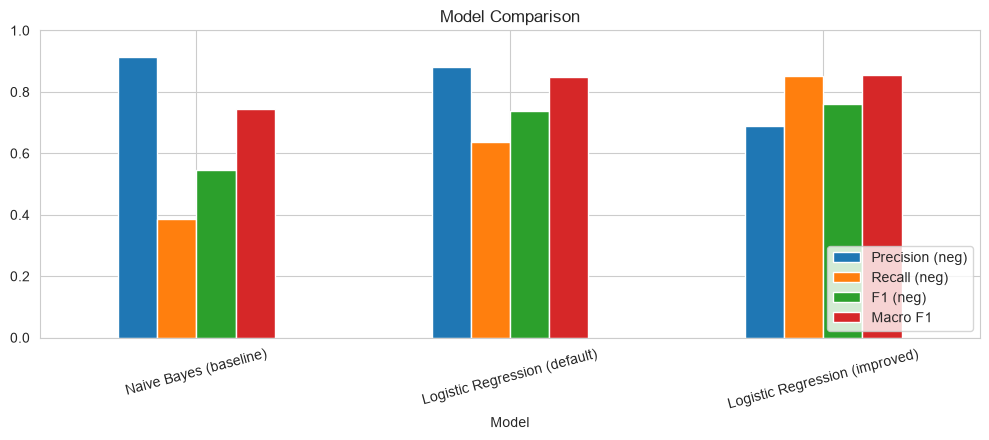

In [61]:
# Compare all three models on the same unseen test set
results = pd.DataFrame([evaluate("Naive Bayes (baseline)", y_test, nb_pred),
                        evaluate("Logistic Regression (default)", y_test, lr_pred),
                        evaluate("Logistic Regression (improved)", y_test, best_pred)]).set_index("Model").round(4)
display(results)

# Chart the comparison for the negative class
results[["Precision (neg)", "Recall (neg)", "F1 (neg)", "Macro F1"]].plot(kind="bar", figsize=(10, 4.5), rot=15)
plt.title("Model Comparison")
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

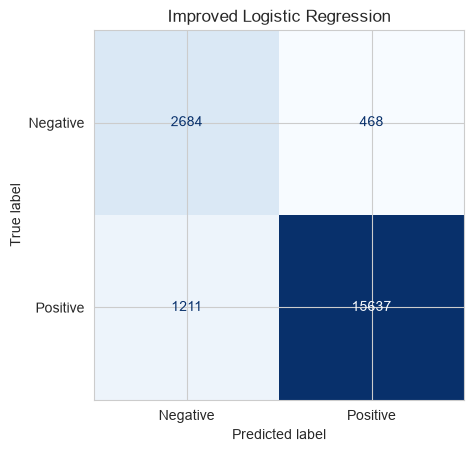

In [62]:
# Confusion matrix of the improved model
cm = confusion_matrix(y_test, best_pred)
ConfusionMatrixDisplay(cm, display_labels=["Negative", "Positive"]).plot(cmap="Blues", colorbar=False)
plt.title("Improved Logistic Regression")
plt.show()

**Impact on results.** Compare the last two rows of the table. With balanced class weights, **recall for the negative class normally rises** (more complaints are caught), usually at the cost of some precision and a small drop in overall accuracy. This is a sensible trade-off for a business that wants to find unhappy customers. If the gains are small on your run, say so honestly in the report.

**Further ideas (future work):** fine-tune a Transformer such as DistilBERT or BERT to capture context and sarcasm; add the review `Summary` as an extra input; use aspect-based sentiment analysis to score taste, price and packaging separately; tune the decision threshold for the negative class.